In [2]:
import os
# This line for the Windows
os.add_dll_directory(r"C:\Users\PC\Desktop\Abrek\openslide-win64-20230414\openslide-win64-20230414\bin")
import datastructure.dataset as dataset
import arguments.setting as setting

In [3]:
data_directories = ["../single_data"]
working_directory = "../workdirtest2/"
csv_file = "patients_fixed.csv"
qupath_project_file = "../qupath_project/project.qpproj"
s = setting.Setting(data_directories, csv_file, working_directory, qupath_project_file)
data = dataset.Dataset(s)

Initial 1567 patients
 B529-23 doesn't have a valid wsi(check bugi names)
 B420-21 doesn't have a valid wsi(check bugi names)
 B1867-21 doesn't have a valid wsi(check bugi names)
 B1388-22 doesn't have a valid wsi(check bugi names)
 B340-19 doesn't have a valid wsi(check bugi names)
 B637-23 doesn't have a valid wsi(check bugi names)
 B1000-13 doesn't have a valid wsi(check bugi names)
 B64-23 doesn't have a valid wsi(check bugi names)
 B259-19 doesn't have a valid wsi(check bugi names)
 B249-19 doesn't have a valid wsi(check bugi names)
 B174-21 doesn't have a valid wsi(check bugi names)
 B126-17 doesn't have a valid wsi(check bugi names)
 B47-17 doesn't have a valid wsi(check bugi names)
 B10-20 doesn't have a valid wsi(check bugi names)
 B1666-18 doesn't have a valid wsi(check bugi names)
 B1452-21 doesn't have a valid wsi(check bugi names)
 B1166-19 doesn't have a valid wsi(check bugi names)
 B1009-21 doesn't have a valid wsi(check bugi names)
 B287-17 doesn't have a valid wsi(chec

In [9]:
import numpy as np

def min_max_image(img):
    img_min = np.min(img, axis = (0, 1))
    img_max = np.max(img, axis = (0, 1))
    return (img - img_min) / (img_max - img_min)

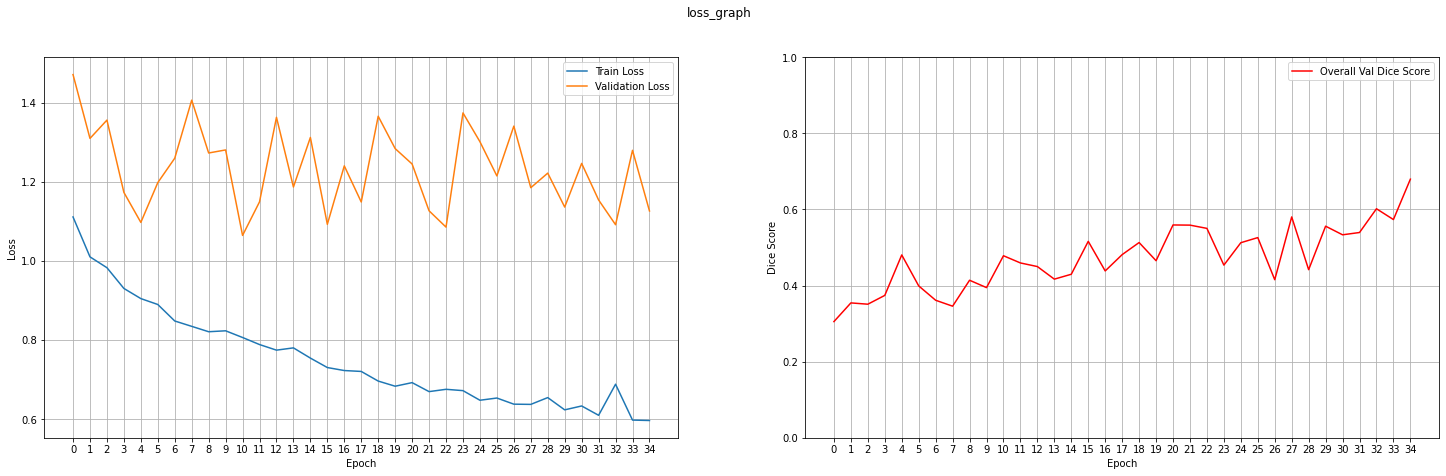

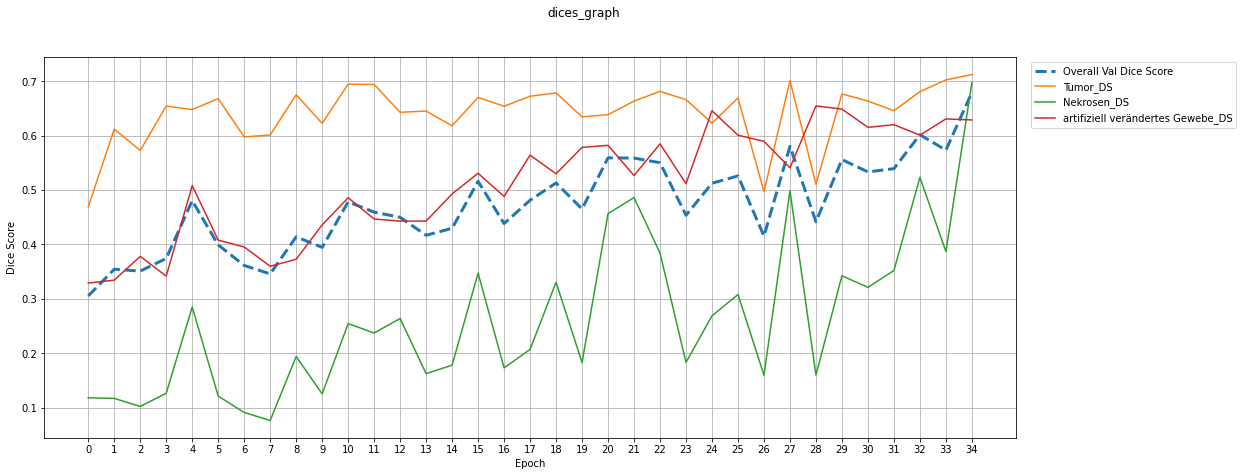

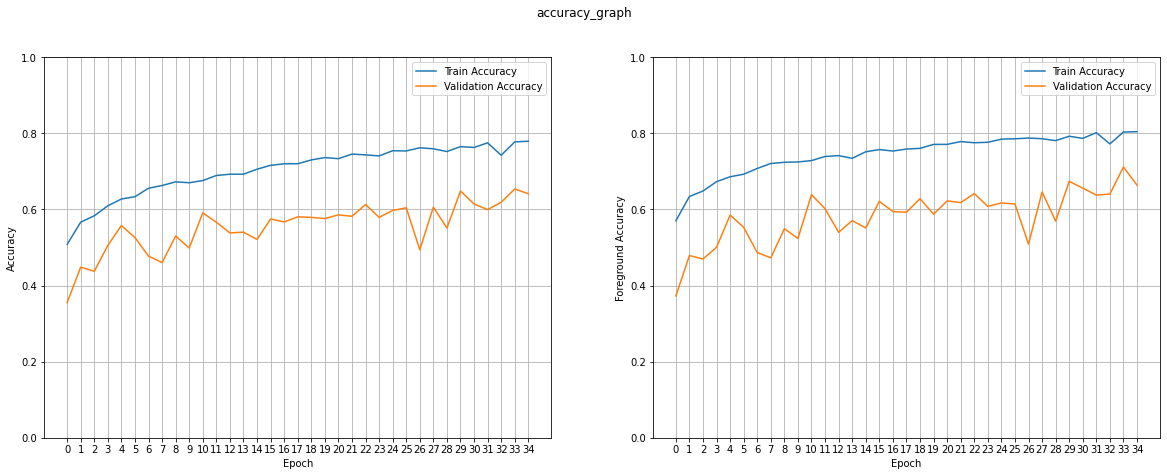

In [11]:
from utils.helper import plot_loss
from utils.helper import plot_dices
from utils.helper import plot_accuracy
logdir = r"C:\Users\PC\Desktop\Fiverr\Max_Pathology\run35"
plot_loss(logdir, "loss_graph")
plot_dices(logdir, "dices_graph")
plot_accuracy(logdir, "accuracy_graph")

['B85-17']


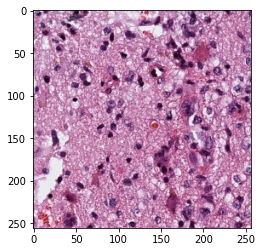

In [12]:
import matplotlib.pyplot as plt

patient = data.get_test_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()
plt.imshow(min_max_image(wsi.tiles[0][0].get_image(wsi.image)))

In [13]:
project = wsi.get_qupath_project()

In [14]:
project.images[2].downsample_levels

[{'downsample': 1.0, 'width': 130560, 'height': 105984},
 {'downsample': 2.0, 'width': 65280, 'height': 52992},
 {'downsample': 4.0, 'width': 32640, 'height': 26496},
 {'downsample': 8.0, 'width': 16320, 'height': 13248},
 {'downsample': 16.0, 'width': 8160, 'height': 6624},
 {'downsample': 32.0, 'width': 4080, 'height': 3312},
 {'downsample': 64.0, 'width': 2040, 'height': 1656},
 {'downsample': 128.0, 'width': 1020, 'height': 828},
 {'downsample': 256.0, 'width': 510, 'height': 414}]

C:\Users\PC\AppData\Local\Programs\Python\Python39\lib\site-packages\tiffslide\tiffslide.py:750: UserWarning: hamamatsu-format metadata parsing only partially implemented!
  return getattr(self, f"parse_{fmt}")()  # type: ignore


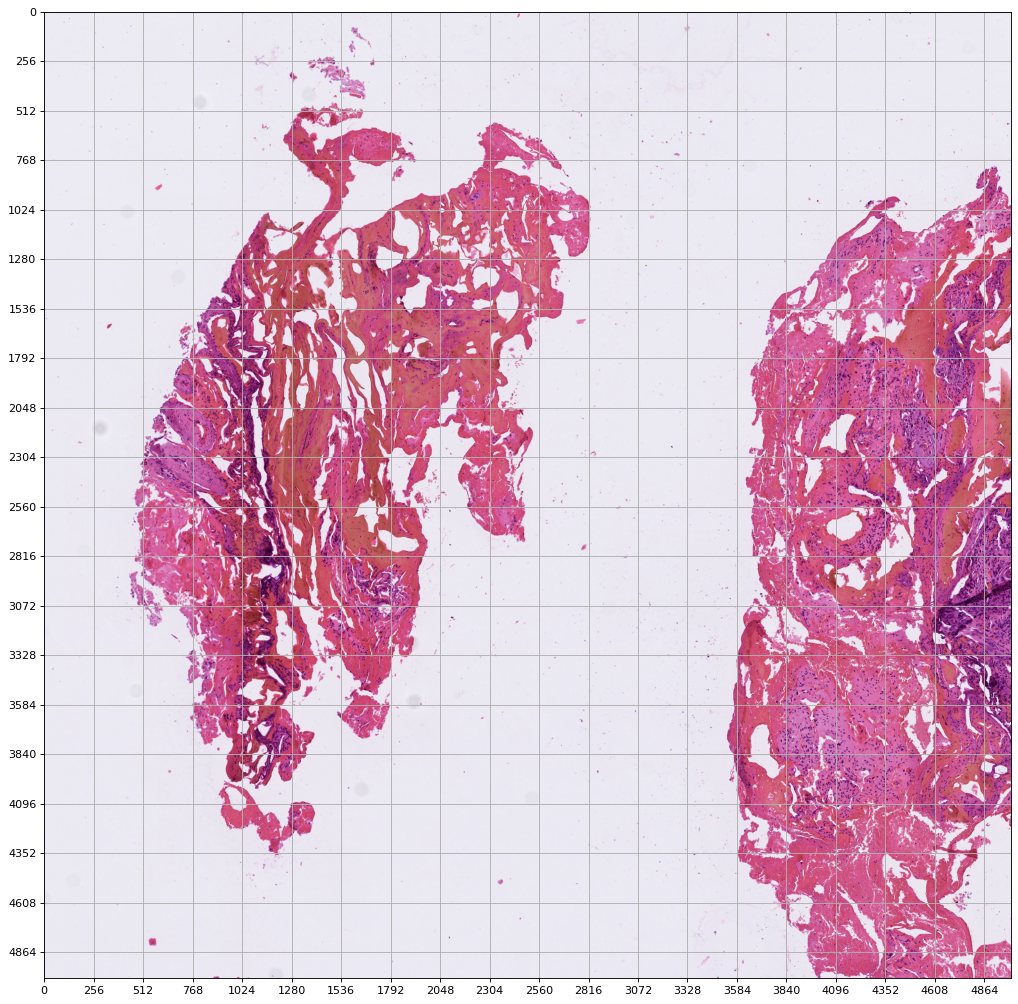

In [15]:
plt.figure(figsize=(16, 16), dpi=80)
major_ticks = np.arange(0, 5000, 256)
plt.xticks(major_ticks)
plt.yticks(major_ticks)
arr = project.get_tile(2, (32640 / 8 + 7000, 26496 / 8 + 9000), (5000, 5000), 2, ret_array = True)
plt.grid(which='both')
plt.imshow(arr)
plt.savefig("example_patches.png")

In [16]:
from histomicstk.preprocessing.color_normalization import reinhard
from histomicstk.saliency.tissue_detection import (
    get_slide_thumbnail, get_tissue_mask)

In [17]:
n_classes = len(wsi.qupath_project.path_classes) - 1

for index, c in enumerate(wsi.qupath_project.path_classes[:-1]):
    print(f"Class {c.name} returned as the channel {(index - 1 - n_classes) % n_classes} in MOTHI")

Class Tumor returned as the channel 15 in MOTHI
Class Hirnparenchym returned as the channel 0 in MOTHI
Class Infiltrationszone returned as the channel 1 in MOTHI
Class Blutung returned as the channel 2 in MOTHI
Class Luftblasen returned as the channel 3 in MOTHI
Class Haare returned as the channel 4 in MOTHI
Class Falten returned as the channel 5 in MOTHI
Class Risse returned as the channel 6 in MOTHI
Class Nekrosen returned as the channel 7 in MOTHI
Class Pseudopalisaden returned as the channel 8 in MOTHI
Class Artefakt returned as the channel 9 in MOTHI
Class artifiziell verändertes Gewebe returned as the channel 10 in MOTHI
Class Nekrose und Blutung returned as the channel 11 in MOTHI
Class Pränekrose returned as the channel 12 in MOTHI
Class out of focus returned as the channel 13 in MOTHI
Class Filzstift returned as the channel 14 in MOTHI


ImageEntries(['B7-18_HE_Hamamatsu_40x.ndpi', 'B9-18_HE_Hamamatsu_40x.ndpi', 'B11-18_HE_Hamamatsu_40x.ndpi', 'B17-19_HE_Hamamatsu_40x.ndpi', 'B20-16_HE_Hamamatsu_40x.ndpi', 'B27-19_HE_Hamamatsu_40x.ndpi', 'B30-18_HE_Hamamatsu_40x.ndpi', 'B35-18_1_HE_Hamamatsu_40x.ndpi', 'B35-18_2_HE_Hamamatsu_40x.ndpi', 'B36-17_1_HE_Hamamatsu_40x.ndpi', 'B36-17_2_HE_Hamamatsu_40x.ndpi', 'B37-17_HE_Hamamatsu_40x.ndpi', 'B42-17_HE_Hamamatsu_40x.ndpi', 'B68-18_HE_Hamamatsu_40x.ndpi', 'B85-17_HE_Hamamatsu_40x.ndpi', 'B100-17_HE_Hamamatsu_40x.ndpi', 'B115-17_HE_Hamamatsu_40x.ndpi', 'B127-19_HE_Hamamatsu_40x.ndpi', 'B128-19_HE_Hamamatsu_40x.ndpi', 'B129-19_HE_Hamamatsu_40x.ndpi', 'B132-17_HE_Hamamatsu_40x.ndpi', 'B138-18_HE_Hamamatsu_40x.ndpi', 'B149-16_HE_Hamamatsu_40x.ndpi', 'B157-17_HE_Hamamatsu_40x.ndpi', 'B162-17_HE_Hamamatsu_40x.ndpi', 'B165-19_HE_Hamamatsu_40x.ndpi', 'B177-18_HE_Hamamatsu_40x.ndpi', 'B178-19_HE_Hamamatsu_40x.ndpi', 'B179-17_HE_Hamamatsu_40x.ndpi', 'B181-16_HE_Hamamatsu_40x.ndpi', 'B187-16_HE_Hamamatsu_40x.ndpi', 'B201-18_HE_Hamamatsu_40x.ndpi', 'B205-09_HE_Hamamatsu_40x.ndpi', 'B205-18_1_HE_Hamamatsu_40x.ndpi', 'B205-18_2_HE_Hamamatsu_40x.ndpi', 'B205-18_HE_Hamamatsu_40x.ndpi', 'B23-18_HE_Hamamatsu_40x-006.ndpi'])
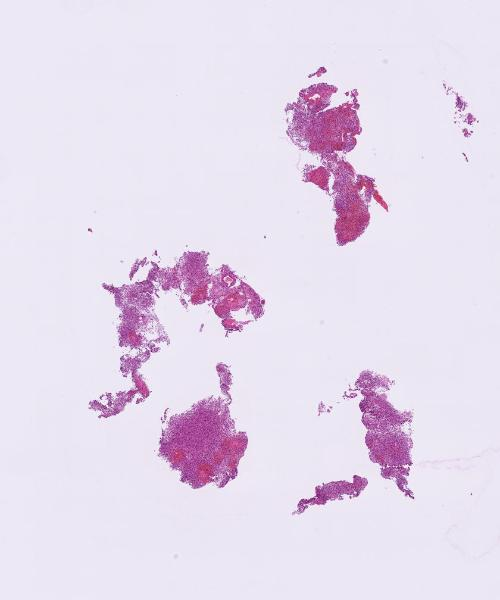
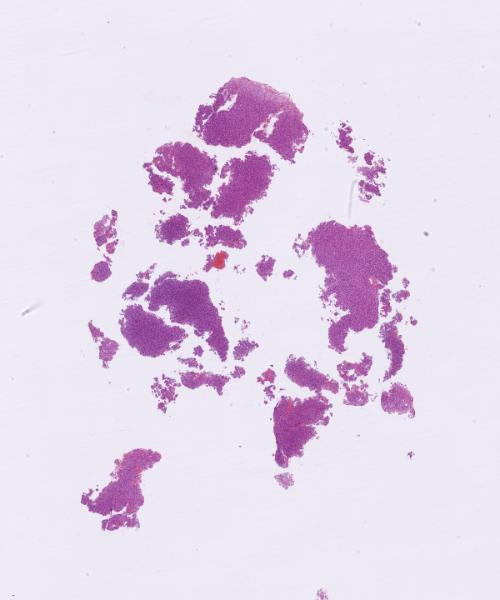
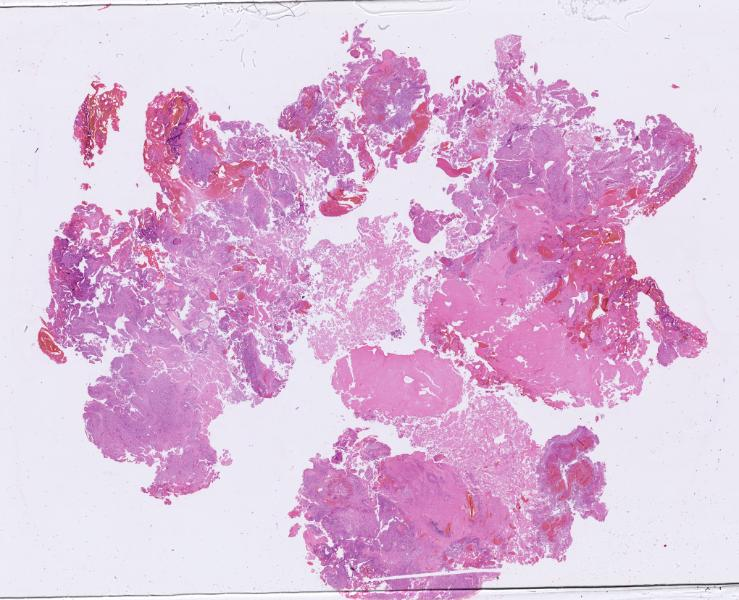
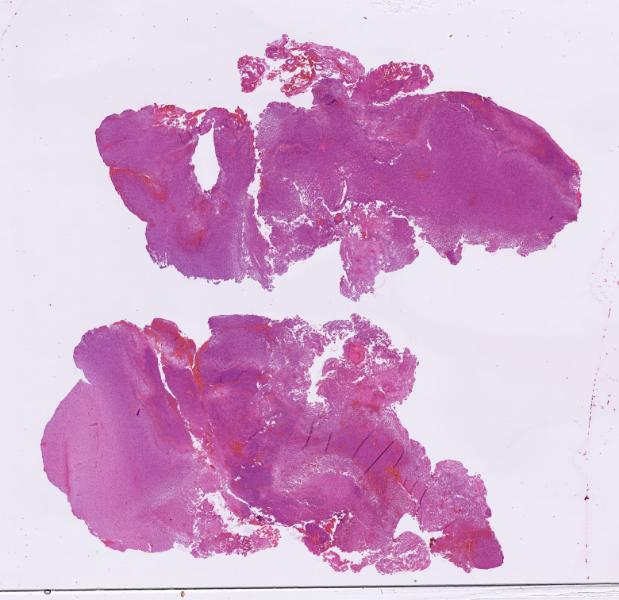
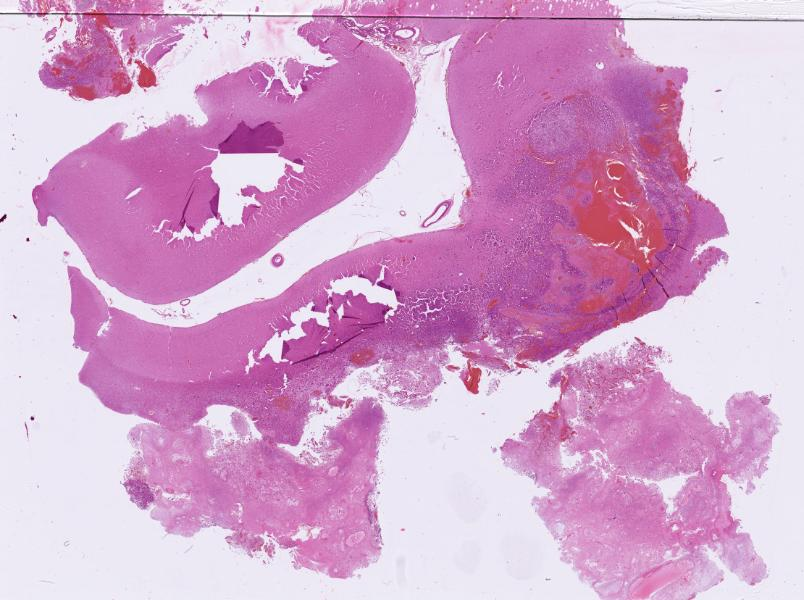
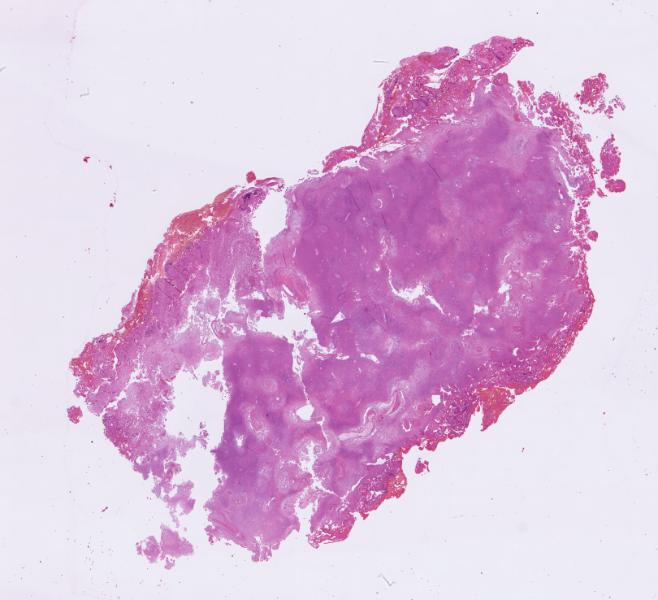
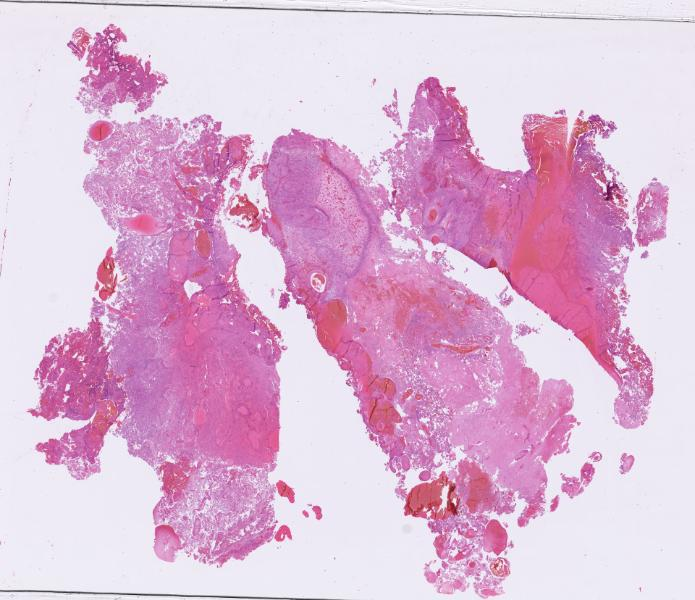
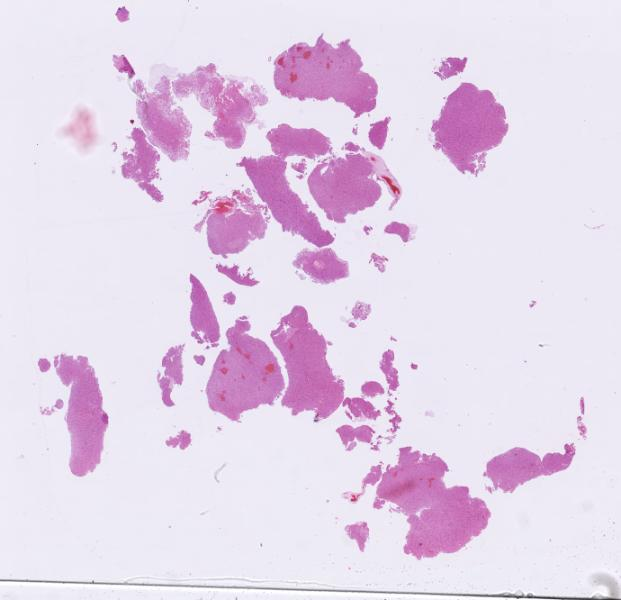
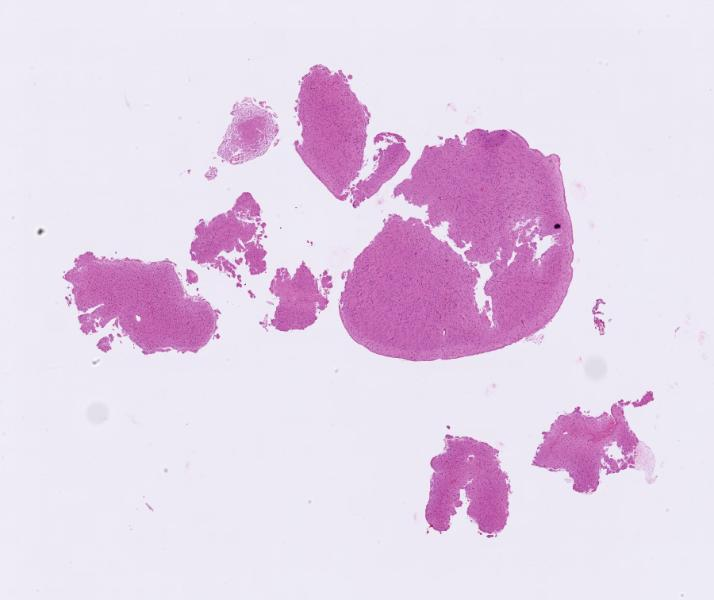
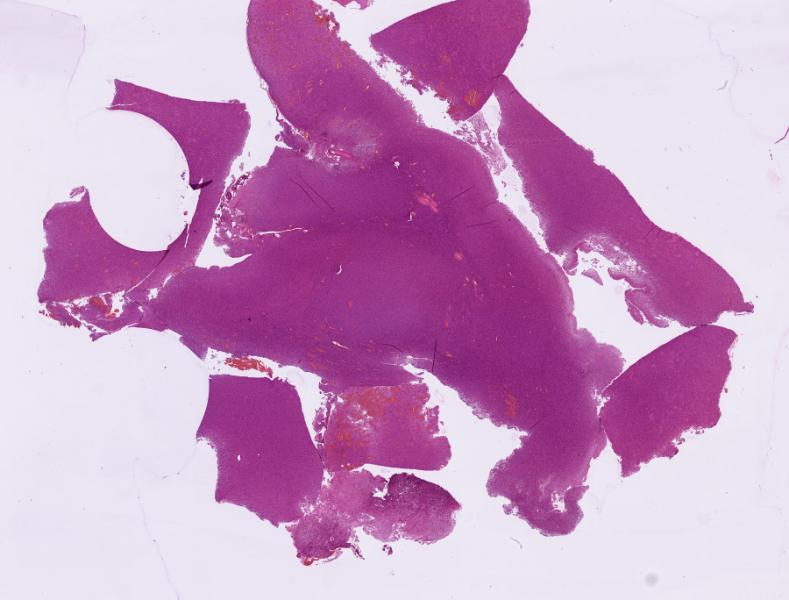
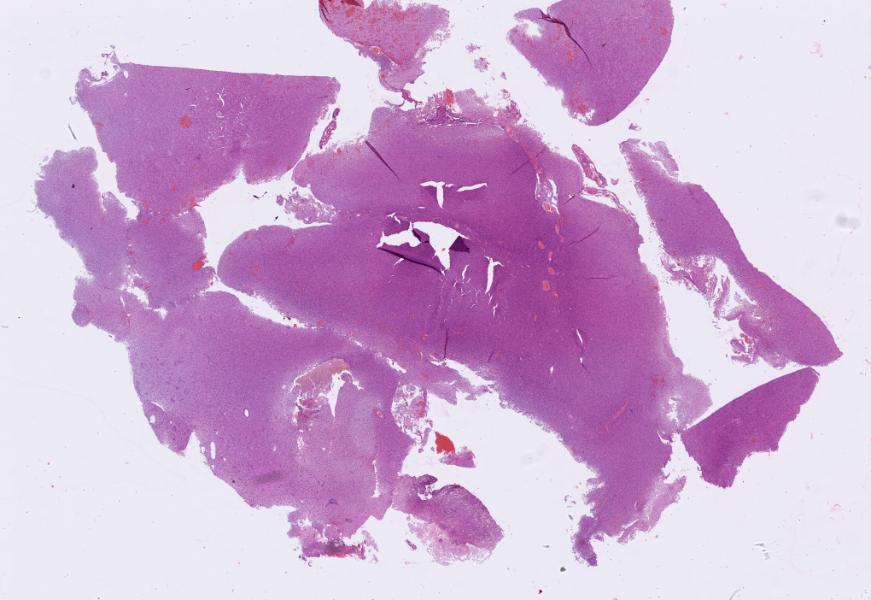
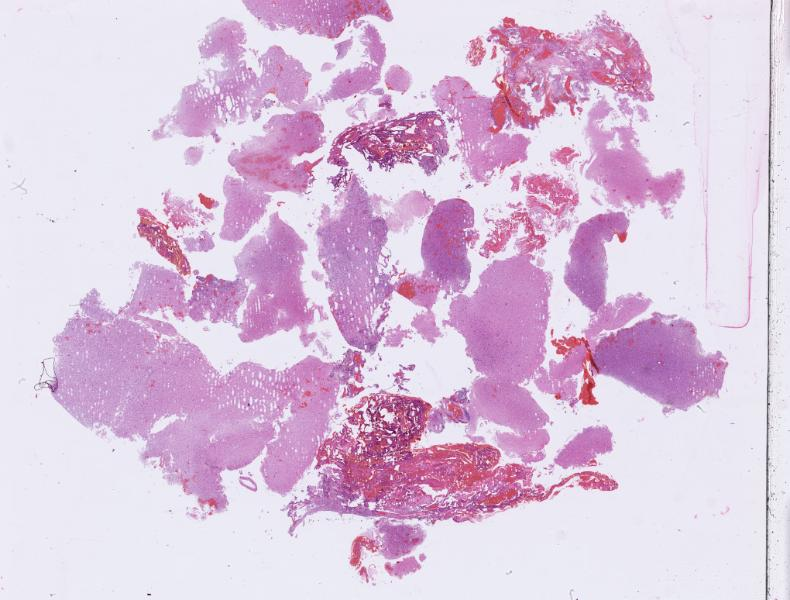
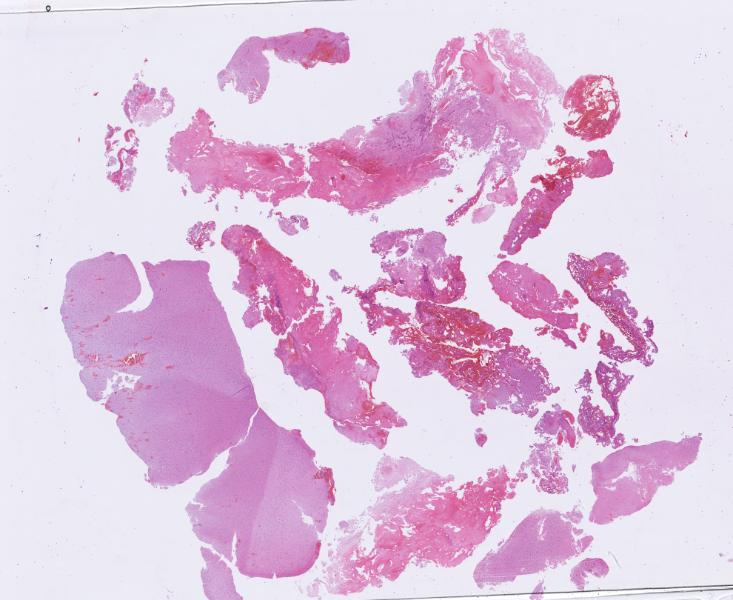
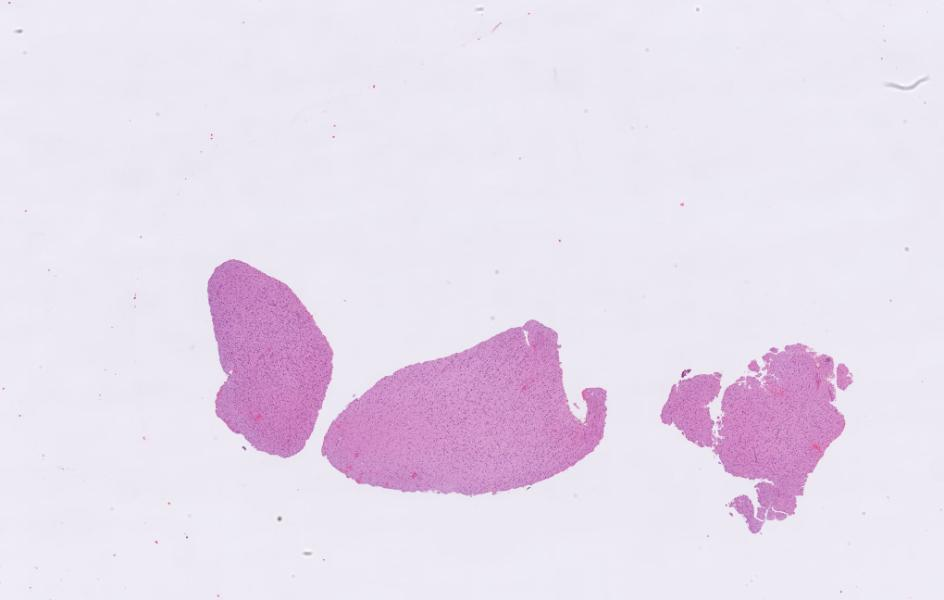
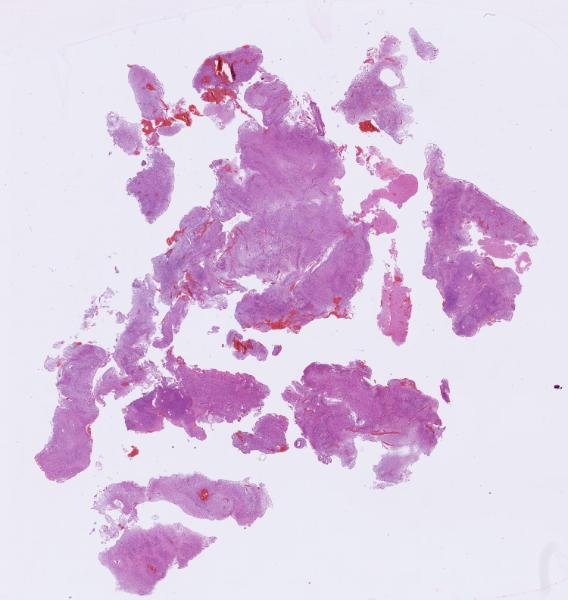
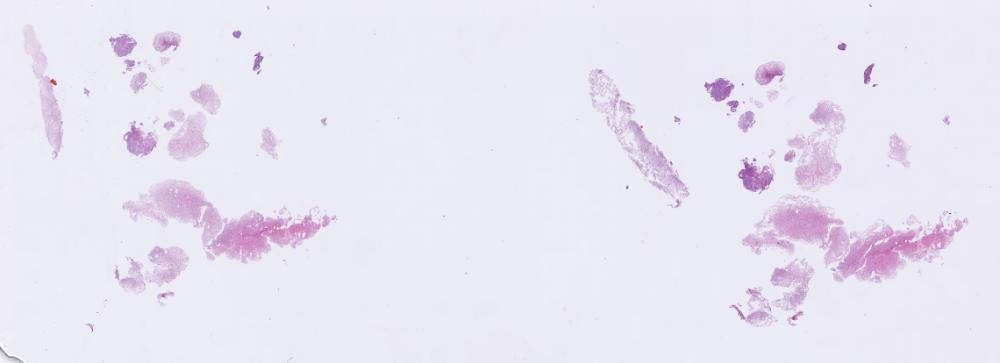
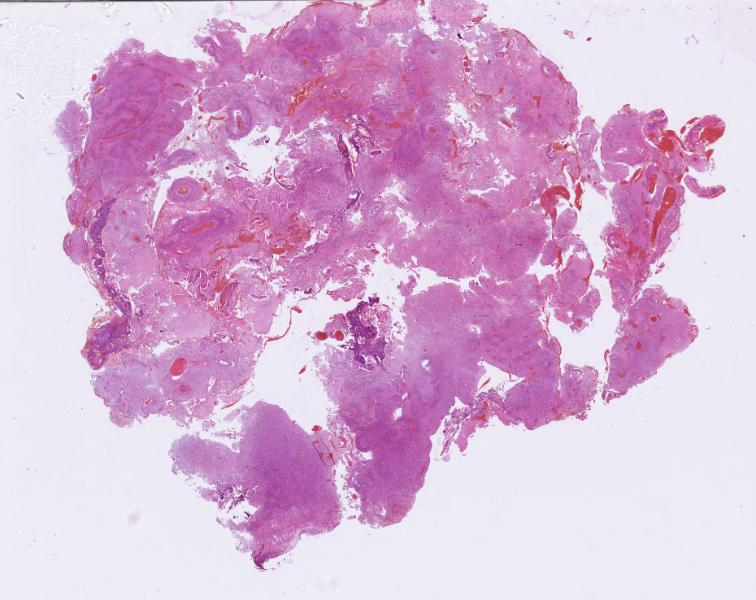
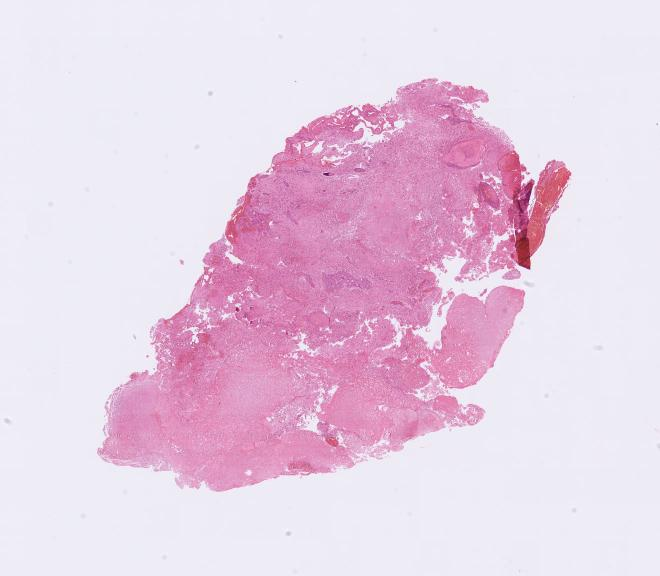
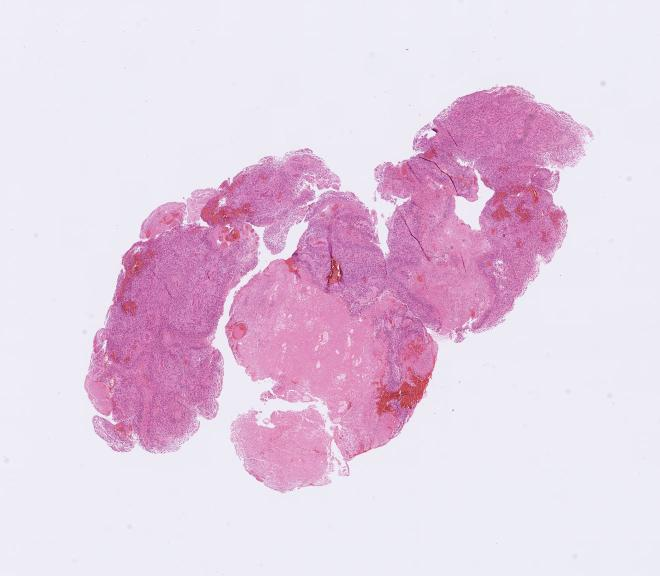
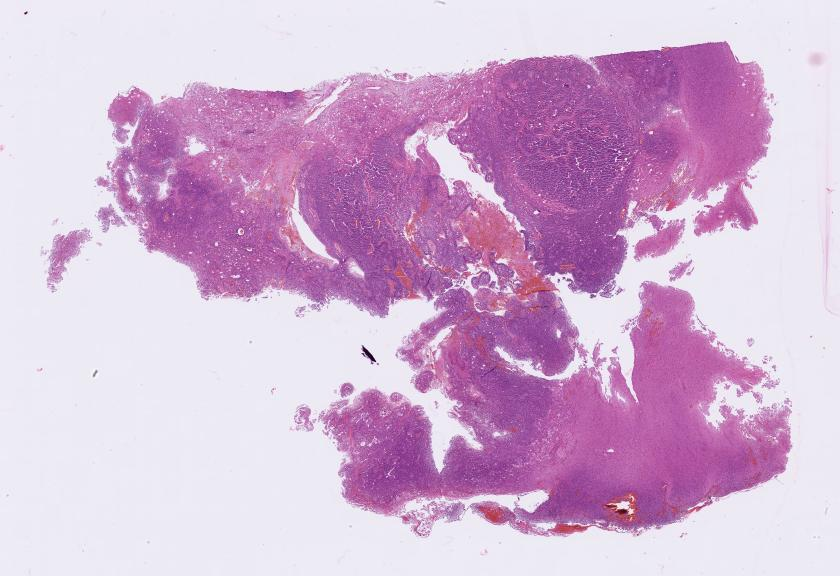
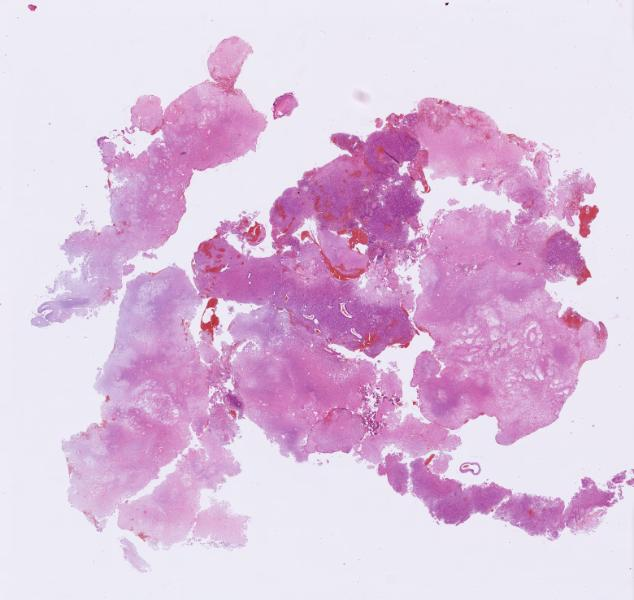
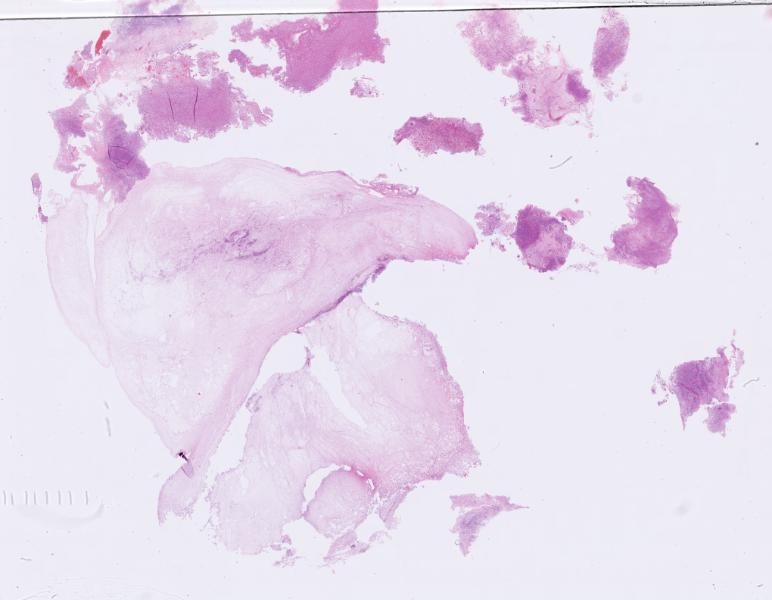
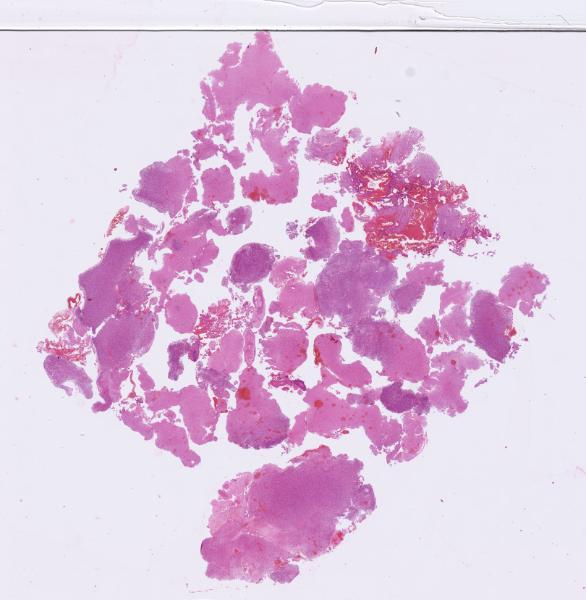
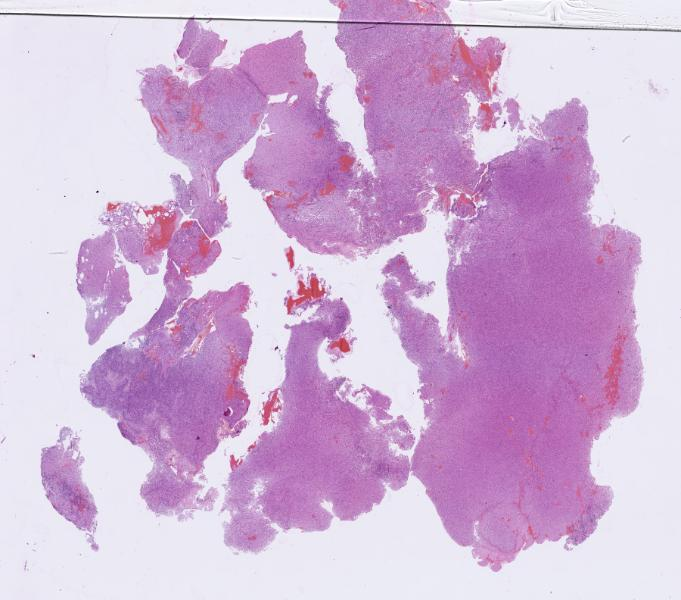
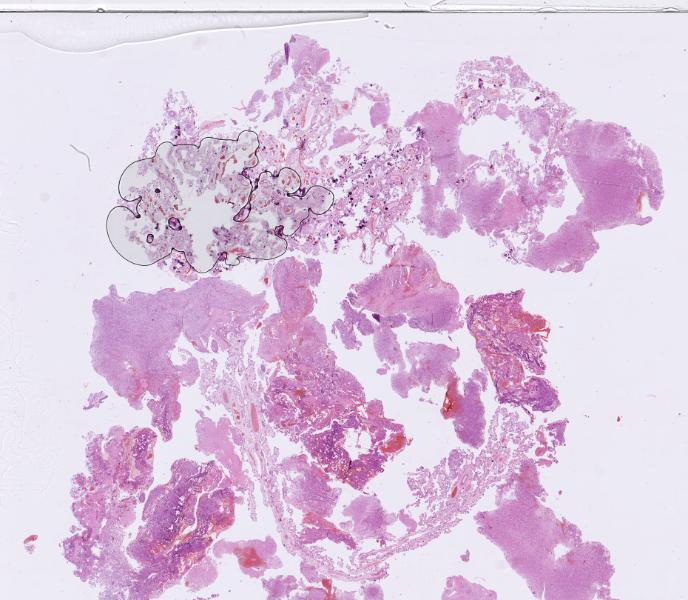
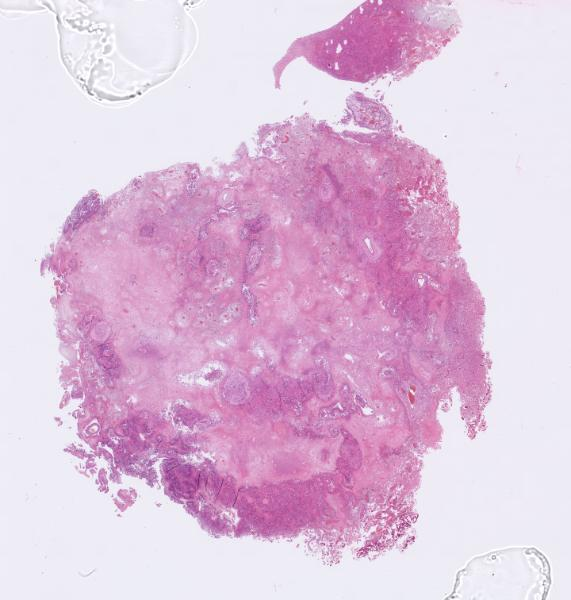
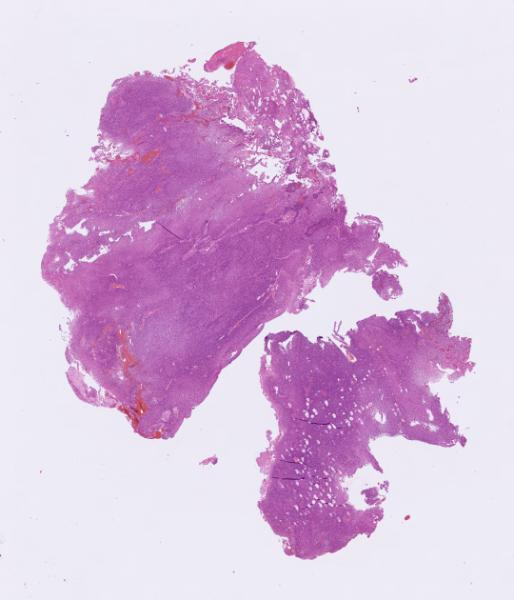
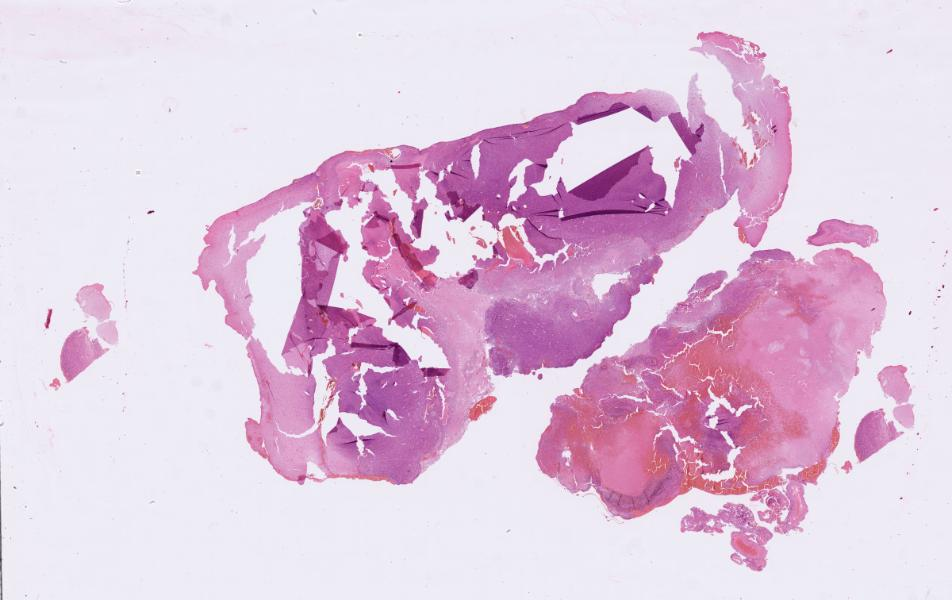
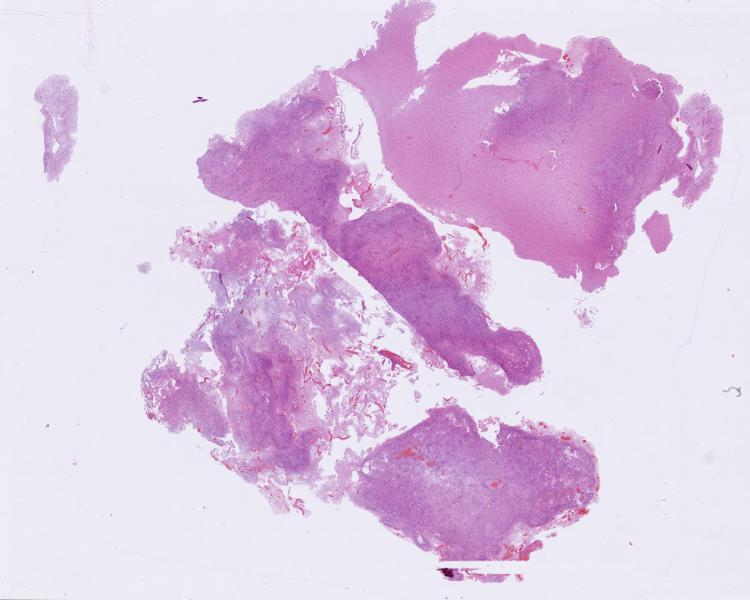
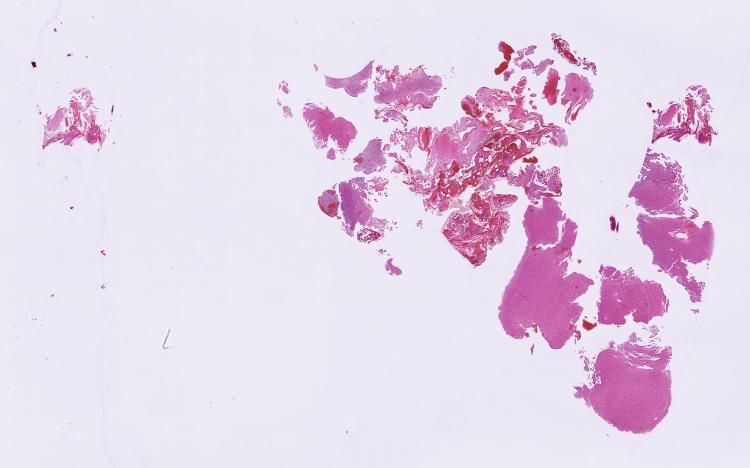
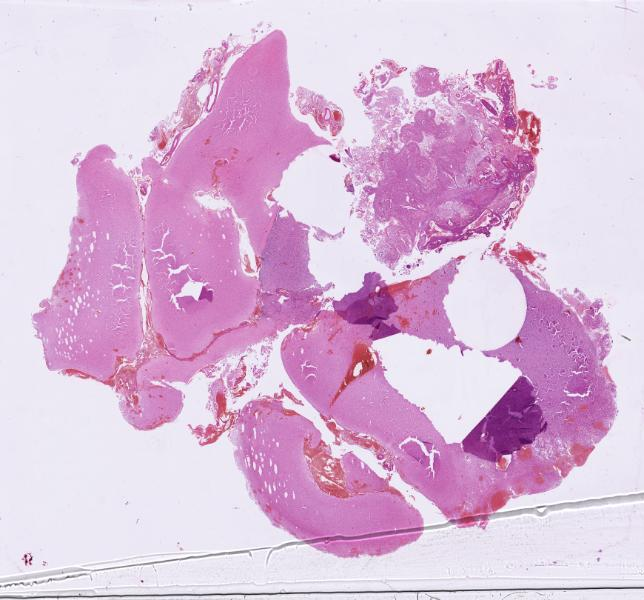
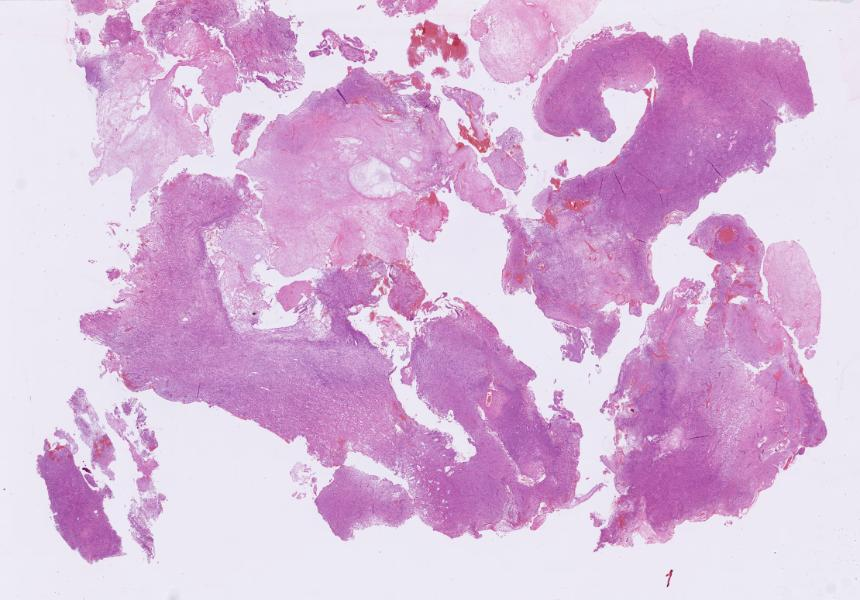
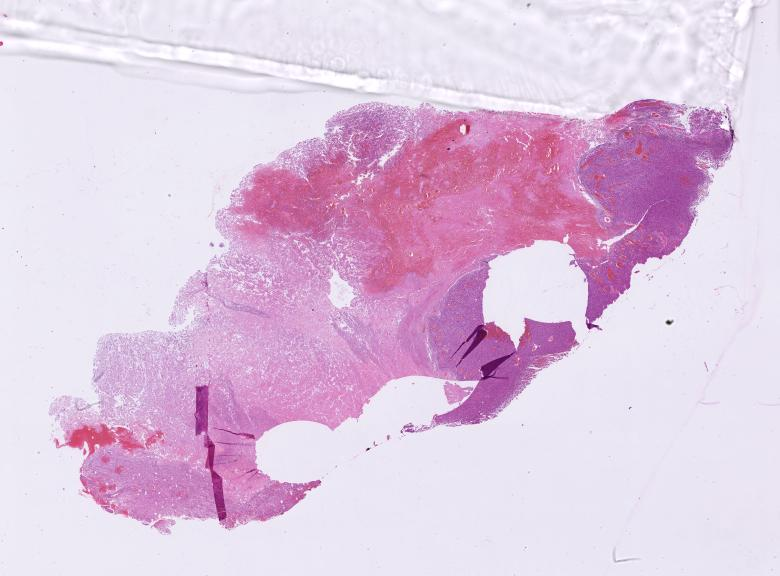
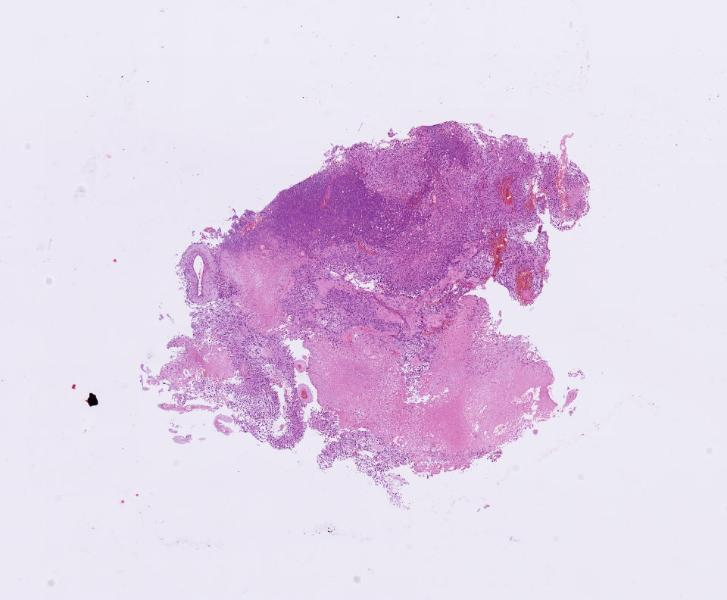
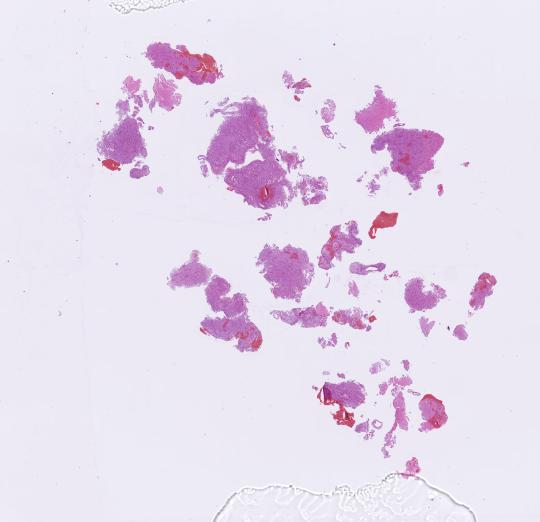
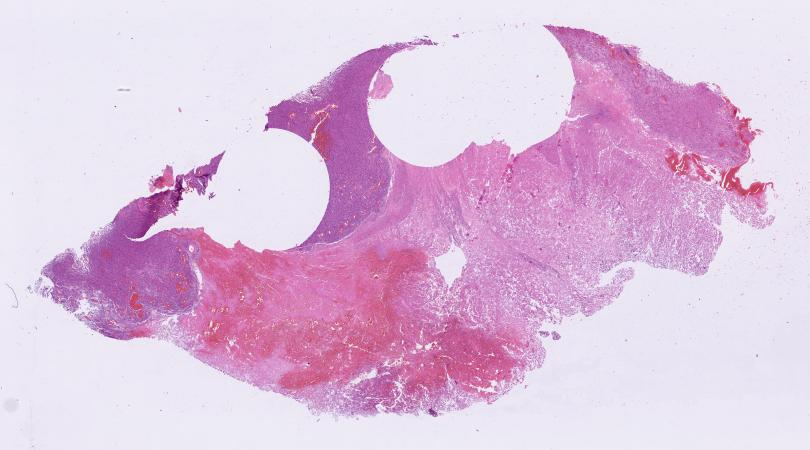
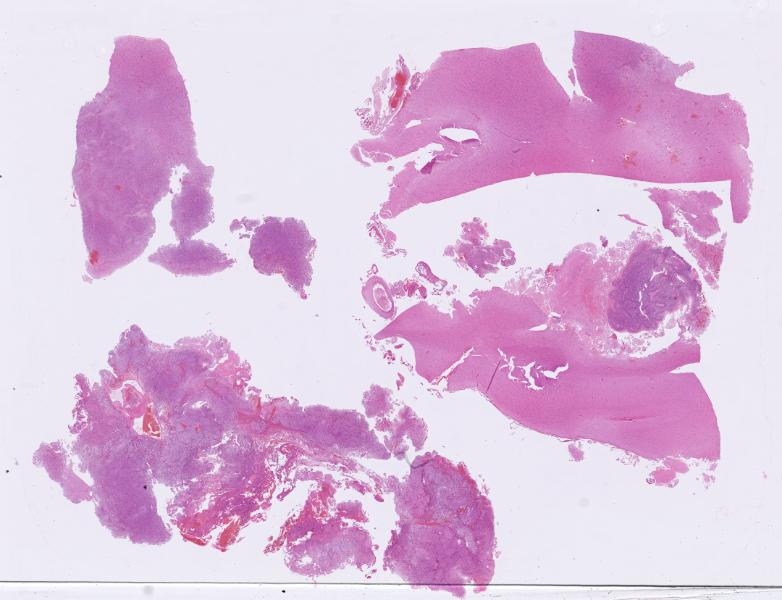

In [18]:
project.images

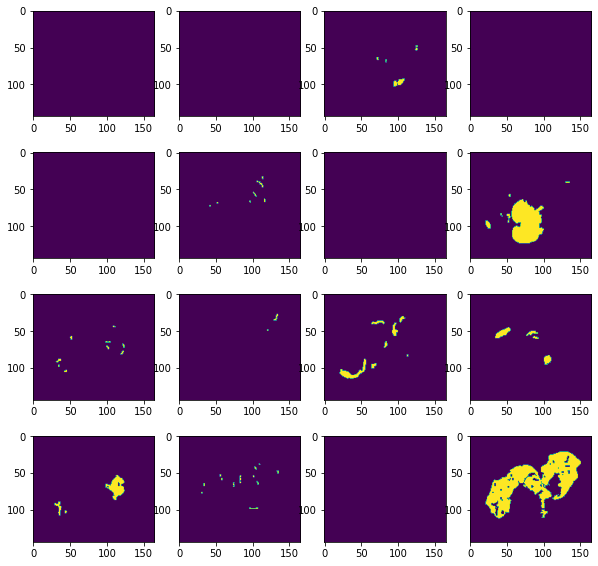

In [20]:
# NOTE: MOTHI shifts the given classes by one to the left. It caused me wasting too much time and I wanted to show it here
# You can see that tumor is in the first list in the upper list. 
# Also you can check the annotations of the B128-19_HE_Hamamatsu_40x.ndpi from the QuPath project
# But here, it is retrieved as the last element :/

arr = wsi.qupath_project.get_tile_annot_mask(18, (0, 0), (165, 144), 8, multichannel = True)

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(16):
    ax[i // 4][i % 4].imshow(arr[i])

In [21]:
patient = data.get_train_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 3 # Class Blutung, since it is not multichannel, it is not shifted to the left

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

['B7-18']


In [22]:
wsi.identifier

'B7-18'

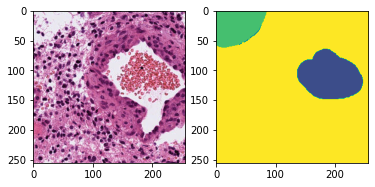

In [23]:
# Explicit example of we are getting the correct tiles

fig, axes = plt.subplots(1, 2)
axes[0].imshow(min_max_image(tiles_with_masks[0][0].get_image(wsi.image)))
axes[1].imshow(tiles_with_masks[0][1], vmin = 0, vmax = 17) # This tile has the unsure class, we will ignore it during training

In [24]:
patient = data.get_train_set()[0][2]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 6 # Class Falten 

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

['B201-18']


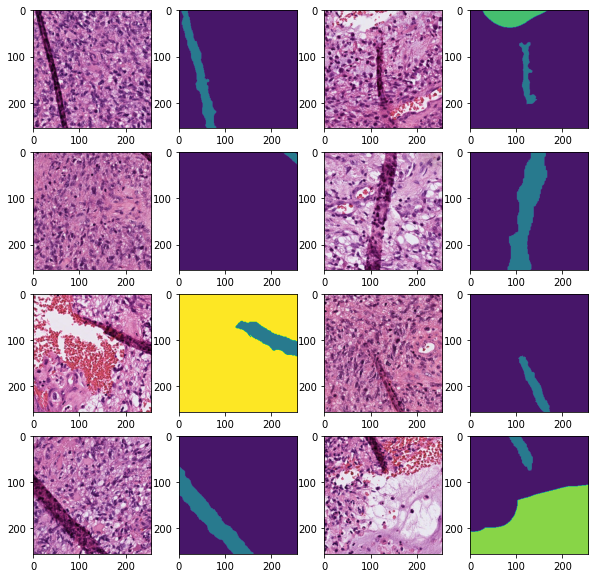

In [25]:
import random

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(4):
    tile1 = random.choice(tiles_with_masks)[0]
    tile2 = random.choice(tiles_with_masks)[0]
    ax[i][0].imshow(min_max_image(tile1.get_image(wsi.image)))
    ax[i][1].imshow(tile1.get_annotation(wsi)[0], vmin = 0, vmax = 17)
    ax[i][2].imshow(min_max_image(tile2.get_image(wsi.image)))
    ax[i][3].imshow(tile2.get_annotation(wsi)[0], vmin = 0, vmax = 17)

In [ ]:
from pathlib import Path
import os

def update_qupath_paths(qupath_project, file_folder_path, delete_not_found = False):
    uri2uri = {}
    images = os.listdir(file_folder_path)
    to_be_deleted = []
    for image in qupath_project.images:
        if image.image_name in images:
            old_path = image.uri
            new_path = "file:/" + os.path.join(file_folder_path, image.image_name).replace("\\", "/")
            uri2uri[old_path] = new_path
            print(f"Path of the {image.image_name} has been changed!")
        elif delete_not_found:
            to_be_deleted.append(image)
            print(f"{image.image_name} has been deleted!")
    qupath_project.update_image_paths(uri2uri = uri2uri)
    for image in to_be_deleted:
        qupath_project.remove_image(image)
    qupath_project.save()

In [16]:
from mothi.tiling_projects import QuPathTilingProject
EXAMPLE_PROJECT = r"C:\Users\PC\Desktop\Fiverr\Max_Pathology\qupath_project\project.qpproj"
qp_project = QuPathTilingProject(EXAMPLE_PROJECT, mode = "r+")

In [30]:
qp_project.get_tile(0, (0, 0), (1000, 1000)).getpixel((0, 0))

(234, 235, 239)

In [5]:
# WARNING DO NOT RUN THIS, IT UPDATES THE QUPATH PROJECT ACCORDING TO GIVEN FOLDER
# update_qupath_paths(qp_project, r"C:\Users\PC\Desktop\Fiverr\Max_Pathology\hamamatsu", delete_not_found = True)

Path of the B7-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B9-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B11-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B17-19_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B20-16_HE_Hamamatsu_40x.ndpi has been changed!
B23-18_HE_Hamamatsu_40x.ndpi has been deleted!
Path of the B27-19_HE_Hamamatsu_40x.ndpi has been changed!
B28-19_HE_Hamamatsu_40x.ndpi has been deleted!
Path of the B30-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B35-18_1_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B35-18_2_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B36-17_1_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B36-17_2_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B37-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B42-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B68-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B85-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B10

In [14]:
# Following part should be changed. Please use the infer_dataset.py for the inference

from datastructure import dataset_torch
import torch
import numpy as np

@torch.no_grad()
def infer_qupath(img_id, model, qupath_project, norm_function = None, level = 2, 
                 n_channels = 1, patch_size = 256, device = "cpu"):
    image = qupath_project.images[img_id]
    downsample, width, height = image.downsample_levels[level].values()
    max_width, max_height = image.width, image.height
    annotations = np.zeros((height, width, n_channels))
    tile_arr = []
    for x in range(0, width, patch_size):
        for y in range(0, height, patch_size):
            tile_width = min(patch_size, width - x)
            tile_height = min(patch_size, height - y)
            tile = qupath_project.get_tile(img_id, (x * (2 ** level), y * (2 ** level)), 
                                           size = (tile_width,
                                                   tile_height),
                                           downsample_level = level)
            tile_arr.append(tile)
            if norm_function:
                tile = norm_function(tile)
            tile_padded = np.zeros((patch_size, patch_size, tile.shape[2]), dtype = np.float32)
            tile_padded[:tile.shape[0], :tile.shape[1]] = tile
            tile_model_sample = torch.tensor(np.transpose(tile_padded[None], [0, 3, 1, 2]), dtype = torch.float).to(device)
            inter = model(tile_model_sample).cpu().numpy()
            logits = inter[0]
            annotations[y : y + tile_height, x : x + tile_width] = logits.argmax(axis = 0).astype(int)[:tile_height, :tile_width, None]
            tile_arr.append(tile_padded)
    return image, annotations, tile_arr

In [9]:
from datastructure import dataset_torch

network_settings = s.get_network_setting()
data_settings = s.get_data_setting()
targets = network_settings.get_targets()
annotation_threshold = network_settings.get_annotation_threshold()

train_set = dataset_torch.PathologyDataset(data.get_train_set(), 
                                          patch_size = data_settings.get_patch_size(),
                                          targets = targets, 
                                          annotation_threshold = annotation_threshold)

use_background = int(annotation_threshold != 1.0)
all_classes = train_set.classes
if not use_background:
    # There is no background class
    classes = [all_classes[i - 1] for i in targets]
else:
    # There is a background class
    classes = [all_classes[i - 1] for i in targets[1:]]
n_classes = len(classes) + use_background

In [10]:
import numpy as np
# My Tragets are all classes
n = len(train_set)

carr = np.zeros(n_classes)
indexes = np.arange(0, n, 1)
np.random.shuffle(indexes)
for i in range(5000):
    _, y = train_set[indexes[i]]
    for c in range(n_classes):
        carr[c] += (y == c).sum()
    if not i % 1000 and i != 0:
        print(f"{i}: ", end = "")
        for c in carr / carr.sum():
            print(f"{c:.3f}", end = " ")
        print()

1000: 0.105 0.322 0.000 0.084 0.009 0.000 0.000 0.010 0.000 0.134 0.001 0.010 0.256 0.050 0.016 0.006 0.000 
2000: 0.103 0.323 0.000 0.087 0.008 0.000 0.000 0.008 0.000 0.140 0.000 0.012 0.246 0.052 0.013 0.006 0.000 
3000: 0.103 0.324 0.000 0.091 0.008 0.000 0.000 0.009 0.000 0.141 0.000 0.010 0.245 0.051 0.012 0.006 0.000 
4000: 0.104 0.325 0.000 0.090 0.008 0.000 0.000 0.008 0.000 0.136 0.001 0.010 0.248 0.051 0.013 0.005 0.000 


In [12]:
if 0 in targets:
    classes = ["Background"] + [train_set.classes[i - 1] for i in targets[1:]]
else:
    classes = [train_set.classes[i - 1] for i in targets]
t = ""
for i in range(len(carr)):
    print(f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset")
    t += f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset"
    if i != len(carr) - 1:
        t += "\n"

Class Background has 34231510.0 pixels and %10.45 of the dataset
Class Tumor has 107657321.0 pixels and %32.85 of the dataset
Class Hirnparenchym has 0.0 pixels and %0.00 of the dataset
Class Infiltrationszone has 29766440.0 pixels and %9.08 of the dataset
Class Blutung has 2695283.0 pixels and %0.82 of the dataset
Class Luftblasen has 0.0 pixels and %0.00 of the dataset
Class Haare has 0.0 pixels and %0.00 of the dataset
Class Falten has 2401341.0 pixels and %0.73 of the dataset
Class Risse has 0.0 pixels and %0.00 of the dataset
Class Nekrosen has 43890447.0 pixels and %13.39 of the dataset
Class Pseudopalisaden has 205754.0 pixels and %0.06 of the dataset
Class Artefakt has 3097742.0 pixels and %0.95 of the dataset
Class artifiziell verändertes Gewebe has 82062658.0 pixels and %25.04 of the dataset
Class Nekrose und Blutung has 16193642.0 pixels and %4.94 of the dataset
Class Pränekrose has 4064174.0 pixels and %1.24 of the dataset
Class out of focus has 1371196.0 pixels and %0.42 o

In [4]:
# I am testing it with the most common 3 classes right now to see if pixel numbers go wild

from datastructure import dataset_torch

network_settings = s.get_network_setting()
data_settings = s.get_data_setting()
targets = network_settings.get_targets()
annotation_threshold = network_settings.get_annotation_threshold()

train_set = dataset_torch.PathologyDataset(data.get_train_set(), 
                                          patch_size = data_settings.get_patch_size(),
                                          targets = targets, 
                                          annotation_threshold = annotation_threshold)

use_background = int(annotation_threshold != 1.0)
all_classes = train_set.classes
if not use_background:
    # There is no background class
    classes = [all_classes[i - 1] for i in targets]
else:
    # There is a background class
    classes = [all_classes[i - 1] for i in targets[1:]]
n_classes = len(classes) + use_background

import numpy as np
# My Tragets are all classes
n = len(train_set)

carr = np.zeros(n_classes)
indexes = np.arange(0, n, 1)
np.random.shuffle(indexes)
for i in range(5000):
    _, y = train_set[indexes[i]]
    for c in range(n_classes):
        carr[c] += (y == c).sum()
    if not i % 1000 and i != 0:
        print(f"{i}: ", end = "")
        for c in carr / carr.sum():
            print(f"{c:.3f}", end = " ")
        print()
        


1000: 0.279 0.317 0.135 0.268 
2000: 0.291 0.311 0.138 0.260 
3000: 0.288 0.313 0.145 0.254 
4000: 0.292 0.316 0.140 0.252 
Class Background has 93935980.0 pixels and %28.67 of the dataset
Class Tumor has 104900180.0 pixels and %32.01 of the dataset
Class Nekrosen has 46752275.0 pixels and %14.27 of the dataset
Class artifiziell verändertes Gewebe has 82091565.0 pixels and %25.05 of the dataset


In [4]:
# I am testing it with the most common 3 classes right now to see if pixel numbers go wild

from datastructure import dataset_torch

network_settings = s.get_network_setting()
data_settings = s.get_data_setting()
targets = network_settings.get_targets()
annotation_threshold = network_settings.get_annotation_threshold()

train_set = dataset_torch.PathologyDataset(data.get_train_set(), 
                                          patch_size = data_settings.get_patch_size(),
                                          targets = targets, 
                                          annotation_threshold = annotation_threshold)

use_background = int(annotation_threshold != 1.0)
all_classes = train_set.classes
if not use_background:
    # There is no background class
    classes = [all_classes[i - 1] for i in targets]
else:
    # There is a background class
    classes = [all_classes[i - 1] for i in targets[1:]]
n_classes = len(classes) + use_background

import numpy as np
# My Tragets are all classes
n = len(train_set)

carr = np.zeros(n_classes)
indexes = np.arange(0, n, 1)
np.random.shuffle(indexes)
for i in range(5000):
    _, y = train_set[indexes[i]]
    for c in range(n_classes):
        carr[c] += (y == c).sum()
    if not i % 1000 and i != 0:
        print(f"{i}: ", end = "")
        for c in carr / carr.sum():
            print(f"{c:.3f}", end = " ")
        print()
        


1000: 0.018 0.518 0.000 0.005 0.004 0.000 0.000 0.000 0.000 0.180 0.000 0.003 0.232 0.024 0.017 0.000 0.000 
2000: 0.018 0.508 0.000 0.004 0.003 0.000 0.000 0.000 0.000 0.193 0.000 0.002 0.225 0.029 0.019 0.000 0.000 
3000: 0.017 0.505 0.000 0.003 0.003 0.000 0.000 0.000 0.000 0.198 0.000 0.002 0.222 0.029 0.020 0.000 0.000 
4000: 0.018 0.509 0.000 0.004 0.003 0.000 0.000 0.001 0.000 0.192 0.000 0.001 0.218 0.032 0.022 0.000 0.000 


In [6]:
data.get_train_set()[0][0].identifier

'B201-18'

In [5]:
if 0 in targets:
    classes = ["Background"] + [train_set.classes[i - 1] for i in targets[1:]]
else:
    classes = [train_set.classes[i - 1] for i in targets]
t = ""
for i in range(len(carr)):
    print(f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset")
    t += f"Class {classes[i]} has {carr[i]} pixels and %{carr[i] * 100 / carr.sum():.2f} of the dataset"
    if i != len(carr) - 1:
        t += "\n"

Class Background has 6014407.0 pixels and %1.84 of the dataset
Class Tumor has 166112305.0 pixels and %50.69 of the dataset
Class Hirnparenchym has 0.0 pixels and %0.00 of the dataset
Class Infiltrationszone has 1306816.0 pixels and %0.40 of the dataset
Class Blutung has 1129359.0 pixels and %0.34 of the dataset
Class Luftblasen has 0.0 pixels and %0.00 of the dataset
Class Haare has 0.0 pixels and %0.00 of the dataset
Class Falten has 160077.0 pixels and %0.05 of the dataset
Class Risse has 0.0 pixels and %0.00 of the dataset
Class Nekrosen has 62869066.0 pixels and %19.19 of the dataset
Class Pseudopalisaden has 0.0 pixels and %0.00 of the dataset
Class Artefakt has 468808.0 pixels and %0.14 of the dataset
Class artifiziell verändertes Gewebe has 71562351.0 pixels and %21.84 of the dataset
Class Nekrose und Blutung has 10732906.0 pixels and %3.28 of the dataset
Class Pränekrose has 7323905.0 pixels and %2.24 of the dataset
Class out of focus has 0.0 pixels and %0.00 of the dataset
Cl

In [25]:
print(t, file = open("classes_train_new.txt", "w"))

In [39]:


model = unet.UNet(network_settings.get_in_channels(),
                n_classes,
                network_settings.get_depth(),
                network_settings.get_wf(),
                True,
                network_settings.get_batch_norm(),
                network_settings.get_up_mode())

NameError: name 'unet' is not defined